## **Cell 1: Imports and config**

In [1]:
import sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch

# ---- CONFIG: change DATA_ROOT if your folder is elsewhere ----
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (PROJECT_ROOT / "data").exists(), f"Wrong project root: {PROJECT_ROOT}. Start Jupyter from the project folder."
DATA_ROOT    = PROJECT_ROOT / "data" / "raw"
CATEGORY     = "metal_nut"
CAT_DIR      = DATA_ROOT / CATEGORY
REPORT_DIR   = PROJECT_ROOT / "reports" / "metrics"
FIG_DIR      = PROJECT_ROOT / "reports" / "figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT)
print("Category dir :", CAT_DIR, "| exists:", CAT_DIR.exists())

Project root : c:\Users\ASUS\Desktop\AI_Projects\Industrial-defect-detection
Category dir : c:\Users\ASUS\Desktop\AI_Projects\Industrial-defect-detection\data\raw\metal_nut | exists: True


In [2]:
for p in sorted(DATA_ROOT.iterdir()):
    print(("DIR  " if p.is_dir() else "FILE ") + p.name)

FILE .gitkeep
DIR  metal_nut
FILE metal_nut.tar.xz


In [3]:
import tarfile
archive = DATA_ROOT / "metal_nut.tar.xz"

if (DATA_ROOT / "metal_nut").exists():
    print("Already extracted, skipping.")
else:
    with tarfile.open(archive) as tar:
        tar.extractall(DATA_ROOT, filter="data")

Already extracted, skipping.


In [4]:
for p in sorted(CAT_DIR.iterdir()):
    print(("DIR  " if p.is_dir() else "FILE ") + p.name)

DIR  ground_truth
FILE license.txt
FILE readme.txt
DIR  test
DIR  train


## **Cell 2: Environment check**

In [5]:
print("Python      :", sys.version.split()[0], "|", platform.system())
print("PyTorch     :", torch.__version__)
print("CUDA avail. :", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print("GPU         :", p.name)
    print("VRAM (GB)   :", round(p.total_memory / 1e9, 2))

Python      : 3.11.17 | Windows
PyTorch     : 2.7.1+cu118
CUDA avail. : True
GPU         : NVIDIA GeForce RTX 3050 Laptop GPU
VRAM (GB)   : 4.29


## **Cell 3: Folder structure**

In [6]:
assert CAT_DIR.exists(), f"Not found: {CAT_DIR}. Fix DATA_ROOT in the config cell."

for sub in ["train", "test", "ground_truth"]:
    d = CAT_DIR / sub
    print(f"{sub:13s} exists={d.exists()}  ->", sorted(p.name for p in d.iterdir()) if d.exists() else "MISSING")

train         exists=True  -> ['good']
test          exists=True  -> ['bent', 'color', 'flip', 'good', 'scratch']
ground_truth  exists=True  -> ['bent', 'color', 'flip', 'scratch']


## **Cell 4: Build the dataset table**

In [7]:
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp"}

def list_images(folder):
    return sorted(p for p in folder.rglob("*") if p.suffix.lower() in IMG_EXT)

rows = []
# train (normal only)
for p in list_images(CAT_DIR / "train" / "good"):
    rows.append(dict(split="train", defect_type="good", path=p, mask_path=None))
# test
for d in sorted((CAT_DIR / "test").iterdir()):
    if not d.is_dir():
        continue
    for p in list_images(d):
        mask = None
        if d.name != "good":
            mask = CAT_DIR / "ground_truth" / d.name / f"{p.stem}_mask.png"
        rows.append(dict(split="test", defect_type=d.name, path=p, mask_path=mask))

df = pd.DataFrame(rows)

def inspect(p):
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            return im.size[0], im.size[1], im.mode, True
    except Exception:
        return None, None, None, False

info = df["path"].apply(inspect)
df[["width", "height", "mode", "readable"]] = pd.DataFrame(info.tolist(), index=df.index)

df["has_mask"]      = df["mask_path"].apply(lambda m: m is not None and Path(m).exists())
df["mask_expected"] = df["defect_type"] != "good"
df["is_anomalous"]  = (df["defect_type"] != "good").astype(int)
df.head()

,split,defect_type,path,mask_path,width,height,mode,readable,has_mask,mask_expected,is_anomalous
0,train,good,c:\Users\ASUS\Desktop\AI_Projects\Industrial-d...,None,700,700,RGB,True,False,False,0
1,train,good,c:\Users\ASUS\Desktop\AI_Projects\Industrial-d...,None,700,700,RGB,True,False,False,0
2,train,good,c:\Users\ASUS\Desktop\AI_Projects\Industrial-d...,None,700,700,RGB,True,False,False,0
3,train,good,c:\Users\ASUS\Desktop\AI_Projects\Industrial-d...,None,700,700,RGB,True,False,False,0
4,train,good,c:\Users\ASUS\Desktop\AI_Projects\Industrial-d...,None,700,700,RGB,True,False,False,0


## **Cell 5: Summary counts**

In [8]:
print("Train normal images :", ((df.split == "train")).sum())
print("Test normal images  :", ((df.split == "test") & (df.defect_type == "good")).sum())
print("Test defective      :", ((df.split == "test") & (df.defect_type != "good")).sum())
print()
print("Test images per defect type:")
print(df[df.split == "test"].groupby("defect_type").size().to_string())
print()
print("Image sizes (w x h, mode):")
print(df.groupby(["width", "height", "mode"]).size().to_string())

Train normal images : 220
Test normal images  : 22
Test defective      : 93

Test images per defect type:
defect_type
bent       25
color      22
flip       23
good       22
scratch    23

Image sizes (w x h, mode):
width  height  mode
700    700     RGB     335


## **Cell 6: Integrity checks**

In [9]:
bad_imgs = df[~df.readable]
missing_masks = df[df.mask_expected & ~df.has_mask]

# mask size must equal image size
mismatch = []
for _, r in df[df.mask_expected & df.has_mask].iterrows():
    with Image.open(r.mask_path) as m:
        if m.size != (r.width, r.height):
            mismatch.append((str(r.path.name), m.size, (r.width, r.height)))

# every mask file should belong to an image
orphans = []
gt_dir = CAT_DIR / "ground_truth"
if gt_dir.exists():
    expected = set(df.loc[df.mask_expected, "mask_path"].dropna().astype(str))
    for mp in gt_dir.rglob("*_mask.png"):
        if str(mp) not in expected:
            orphans.append(mp)

print("Unreadable images :", len(bad_imgs))
print("Missing masks     :", len(missing_masks))
print("Size mismatches   :", len(mismatch))
print("Orphan masks      :", len(orphans))
if len(bad_imgs) + len(missing_masks) + len(mismatch) + len(orphans) == 0:
    print("\nAudit passed: dataset is consistent.")

Unreadable images : 0
Missing masks     : 0
Size mismatches   : 0
Orphan masks      : 0

Audit passed: dataset is consistent.


## **Cell 7: Count plot**

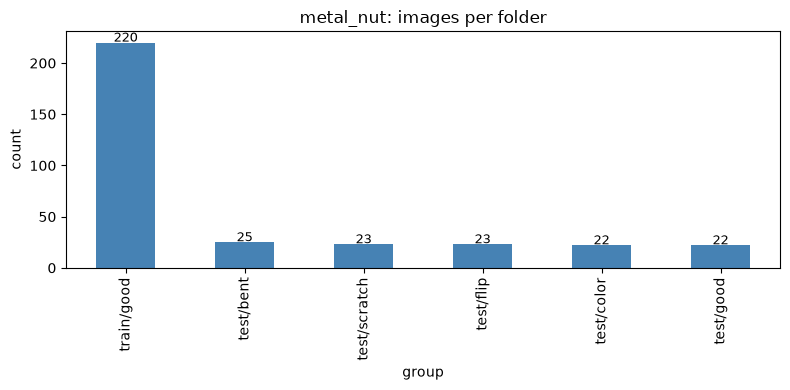

In [10]:
counts = (df.assign(group=np.where(df.split == "train", "train/good", "test/" + df.defect_type))
            .groupby("group").size().sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(8, 4))
counts.plot.bar(ax=ax, color="steelblue")
ax.set_title(f"{CATEGORY}: images per folder")
ax.set_ylabel("count")
for i, v in enumerate(counts.values):
    ax.text(i, v + 1, str(v), ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / f"{CATEGORY}_dataset_counts.png", dpi=150)
plt.show()

## **Cell 8: Normal training images**

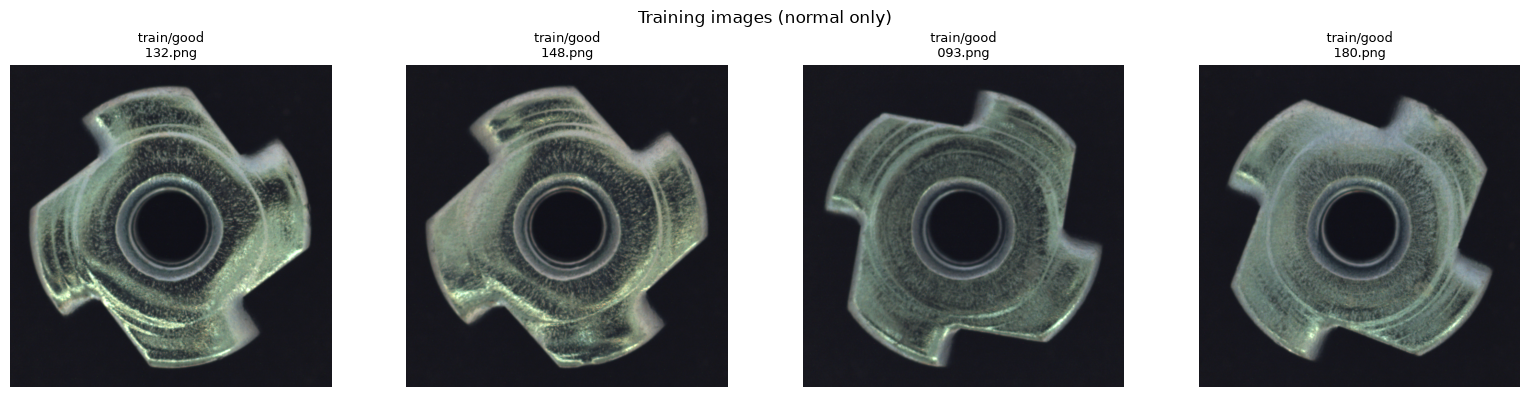

In [11]:
def show_row(rows, title):
    n = len(rows)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    axes = np.atleast_1d(axes)
    for ax, (_, r) in zip(axes, rows.iterrows()):
        ax.imshow(Image.open(r.path).convert("RGB"))
        ax.set_title(f"{r.split}/{r.defect_type}\n{r.path.name}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    return fig

normal = df[(df.split == "train")].sample(4, random_state=42)
fig = show_row(normal, "Training images (normal only)")
fig.savefig(FIG_DIR / f"{CATEGORY}_normal_samples.png", dpi=150)
plt.show()

## **Cell 9: Defective images with mask and overlay**

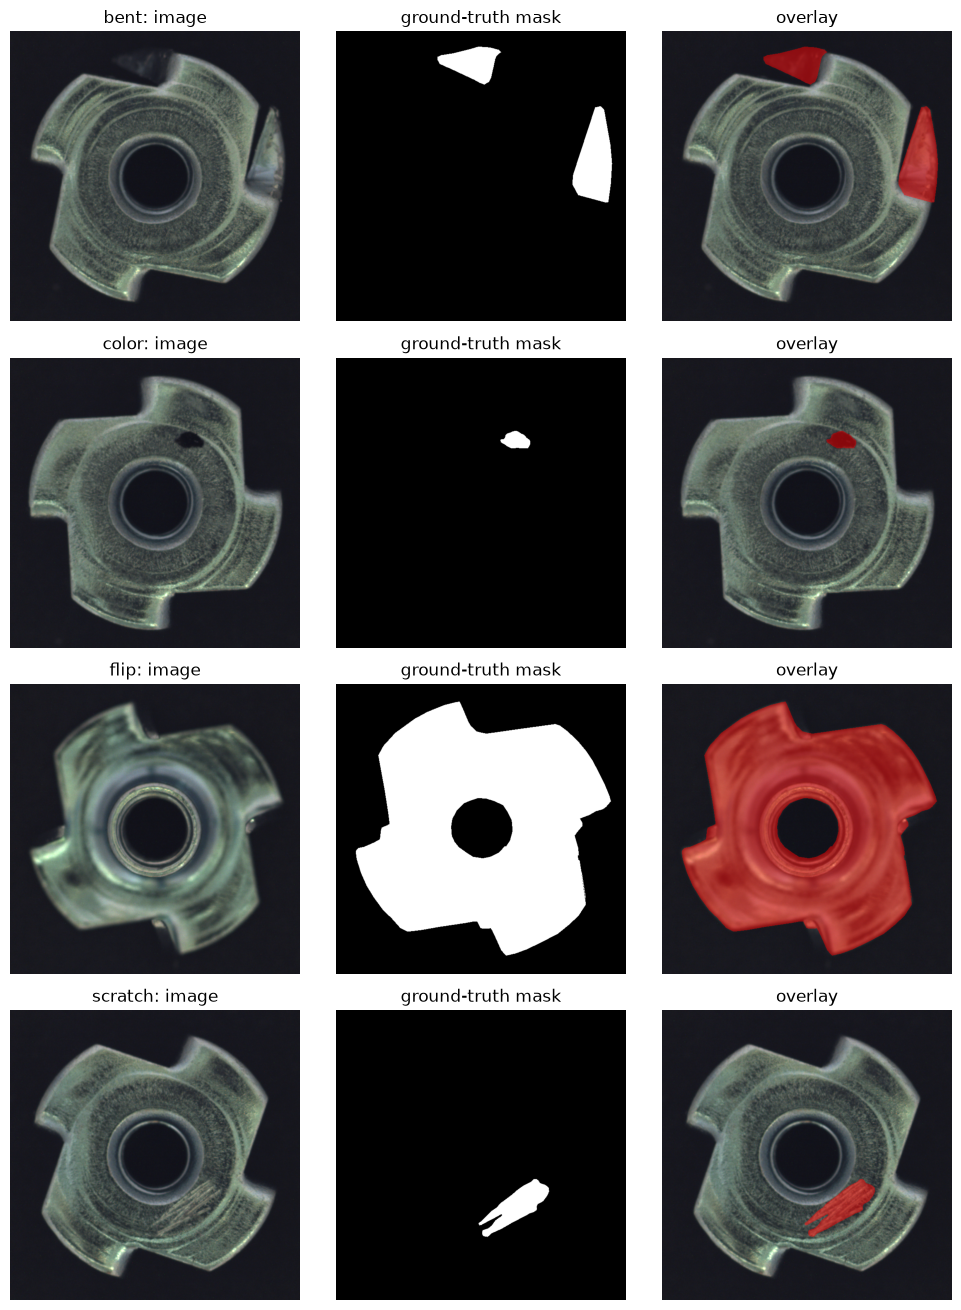

In [12]:
types = sorted(df[(df.split == "test") & (df.defect_type != "good")].defect_type.unique())
fig, axes = plt.subplots(len(types), 3, figsize=(10, 3.3 * len(types)))
axes = np.atleast_2d(axes)

for row_ax, t in zip(axes, types):
    r = df[(df.split == "test") & (df.defect_type == t) & df.has_mask].iloc[0]
    img  = np.array(Image.open(r.path).convert("RGB"))
    mask = np.array(Image.open(r.mask_path).convert("L")) > 0

    overlay = img.copy()
    overlay[mask] = (0.5 * overlay[mask] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)

    row_ax[0].imshow(img);                row_ax[0].set_title(f"{t}: image")
    row_ax[1].imshow(mask, cmap="gray");  row_ax[1].set_title("ground-truth mask")
    row_ax[2].imshow(overlay);            row_ax[2].set_title("overlay")
    for a in row_ax:
        a.axis("off")

plt.tight_layout()
plt.savefig(FIG_DIR / f"{CATEGORY}_defect_samples.png", dpi=150)
plt.show()

## **Cell 10: Save the audit**

In [16]:
out = df.copy()
out["path"] = out["path"].apply(lambda p: Path(p).relative_to(PROJECT_ROOT).as_posix())
out["mask_path"] = out["mask_path"].apply(
    lambda p: Path(p).relative_to(PROJECT_ROOT).as_posix() if p is not None else "")
out.to_csv(REPORT_DIR / f"{CATEGORY}_audit.csv", index=False)

summary = df.groupby(["split", "defect_type"]).size().rename("n_images").reset_index()
summary.to_csv(REPORT_DIR / f"{CATEGORY}_audit_summary.csv", index=False)
print("Saved:", REPORT_DIR / f"{CATEGORY}_audit.csv")
print("Saved:", REPORT_DIR / f"{CATEGORY}_audit_summary.csv")
summary

Saved: c:\Users\ASUS\Desktop\AI_Projects\Industrial-defect-detection\reports\metrics\metal_nut_audit.csv
Saved: c:\Users\ASUS\Desktop\AI_Projects\Industrial-defect-detection\reports\metrics\metal_nut_audit_summary.csv


,split,defect_type,n_images
0,test,bent,25
1,test,color,22
2,test,flip,23
3,test,good,22
4,test,scratch,23
5,train,good,220


## **Cell 11: Label audit**

In [17]:
assert set(df["split"].unique()) == {"train", "test"}

# training images must all be normal
tr = df[df["split"] == "train"]
assert (tr["defect_type"] == "good").all()
assert (tr["is_anomalous"] == 0).all()

# test labels must agree with the folder name
te = df[df["split"] == "test"]
assert (te["is_anomalous"] == (te["defect_type"] != "good").astype(int)).all()

# every defective test image must have a mask
assert te[te["is_anomalous"] == 1]["has_mask"].all()

print("Label audit passed.")
print("Training samples        :", len(tr))
print("Test samples            :", len(te))
print("Defective test samples  :", int(te["is_anomalous"].sum()))

Label audit passed.
Training samples        : 220
Test samples            : 115
Defective test samples  : 93


## **Cell 12: Save run metadata**

In [18]:
import json, datetime

meta = {
    "category": CATEGORY,
    "dataset_root": DATA_ROOT.relative_to(PROJECT_ROOT).as_posix(),
    "n_train_normal": int((df.split == "train").sum()),
    "n_test_normal": int(((df.split == "test") & (df.defect_type == "good")).sum()),
    "n_test_defective": int(((df.split == "test") & (df.defect_type != "good")).sum()),
    "defect_types": sorted(df[df.defect_type != "good"].defect_type.unique().tolist()),
    "original_image_sizes": df[["width", "height"]].drop_duplicates().astype(int).values.tolist(),
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "date": datetime.date.today().isoformat(),
}
with open(REPORT_DIR / f"{CATEGORY}_dataset_meta.json", "w") as f:
    json.dump(meta, f, indent=2)
print(json.dumps(meta, indent=2))

{
  "category": "metal_nut",
  "dataset_root": "data/raw",
  "n_train_normal": 220,
  "n_test_normal": 22,
  "n_test_defective": 93,
  "defect_types": [
    "bent",
    "color",
    "flip",
    "scratch"
  ],
  "original_image_sizes": [
    [
      700,
      700
    ]
  ],
  "python": "3.11.17",
  "torch": "2.7.1+cu118",
  "cuda_available": true,
  "gpu": "NVIDIA GeForce RTX 3050 Laptop GPU",
  "date": "2026-10-12"
}


In [19]:
print(pd.read_csv(REPORT_DIR / f"{CATEGORY}_audit.csv").loc[[0, 230], ["path", "mask_path"]])

                                      path  \
0    data/raw/metal_nut/train/good/000.png   
230   data/raw/metal_nut/test/bent/010.png   

                                             mask_path  
0                                                  NaN  
230  data/raw/metal_nut/ground_truth/bent/010_mask.png  
